# Phase 1 Progress report

This notebook compares AI-assisted analysis with human-only CLIP evaluation. The goal is to show where the findings agree, where they differ, and overall progress achieved by the team in phase 1.


## 1. Load and inspect experiment metadata

We start from the high-level metrics reported in the two analyses. The most important fields are:
- source: whether the result came from the AI-aided notebook or the human-only notebook
- prompt_style: neutral or descriptive
- accuracy: overall classification accuracy
- changed_predictions: number of examples whose prediction changed when the prompt changed



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

project_root = Path('/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies')
output_dir = project_root / 'outputs'

# Summary values extracted from the project reports and local outputs
comparison_df = pd.DataFrame([
    {
        'source': 'AI-aided',
        'prompt_style': 'neutral',
        'accuracy': 0.6233,
        'changed_predictions': 1199,
        'notes': 'AI-assisted report: neutral prompt accuracy'
    },
    {
        'source': 'AI-aided',
        'prompt_style': 'descriptive',
        'accuracy': 0.5230,
        'changed_predictions': 1199,
        'notes': 'AI-assisted report: descriptive prompt accuracy'
    },
    {
        'source': 'Human-only',
        'prompt_style': 'neutral',
        'accuracy': 0.3247,
        'changed_predictions': 2613,
        'notes': 'Local notebook output: neutral prompt accuracy'
    },
    {
        'source': 'Human-only',
        'prompt_style': 'descriptive',
        'accuracy': 0.3342,
        'changed_predictions': 2613,
        'notes': 'Local notebook output: descriptive prompt accuracy'
    }
])

# Order for plotting
comparison_df['prompt_style'] = pd.Categorical(
    comparison_df['prompt_style'], categories=['neutral', 'descriptive'], ordered=True
)
comparison_df['source'] = pd.Categorical(comparison_df['source'], categories=['AI-aided', 'Human-only'], ordered=True)

# Create a clean comparison table
comparison_table = comparison_df[['source', 'prompt_style', 'accuracy', 'changed_predictions']].copy()
comparison_table['accuracy_pct'] = comparison_table['accuracy'] * 100
comparison_table


,source,prompt_style,accuracy,changed_predictions,accuracy_pct
0,AI-aided,neutral,0.6233,1199,62.33
1,AI-aided,descriptive,0.5230,1199,52.30
2,Human-only,neutral,0.3247,2613,32.47
3,Human-only,descriptive,0.3342,2613,33.42


## 2. Visualize prompt-style accuracy comparison

This chart compares neutral and descriptive prompt performance for both the AI-aided and human-only runs. The key point is that both settings are sensitive to prompt wording, but the AI-aided workflow starts from a higher baseline.


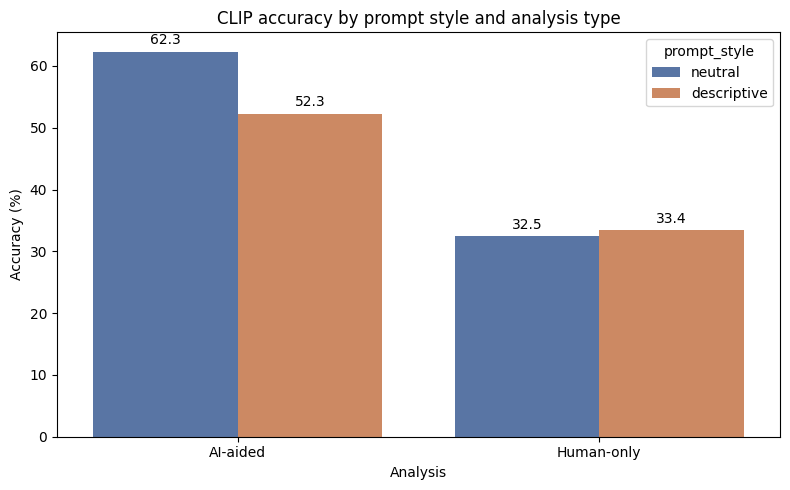

In [3]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=comparison_table,
    x='source',
    y='accuracy_pct',
    hue='prompt_style',
    palette=['#4C72B0', '#DD8452']
)
ax.set_title('CLIP accuracy by prompt style and analysis type')
ax.set_xlabel('Analysis')
ax.set_ylabel('Accuracy (%)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
plt.tight_layout()
plt.show()


### Prompt wording used in each analysis

The exact wording matters. The AI-aided pair used a simple neutral template and a more descriptive genre template, while the human-only notebook used a shorter neutral prompt and a mood-based descriptive prompt.

The AI-aided pair used:
- Neutral: `A book cover of a {genre} book.`
- Descriptive: `A book cover of a romantic love story novel.` / `A book cover of a mysterious crime thriller novel.` / `A book cover of a science fiction or fantasy adventure novel.` / `A book cover of a historical nonfiction book.` / `A book cover of a biography about a person's life.` / `A book cover of a children's illustrated storybook.`

The human-only pair used:
- Neutral: `a book cover in the genre {category}`
- Descriptive: `a visually rich book cover with a strong {category} mood`

Important note: 
In the beginning we didn't discuss which subset of genres we take. So AI-aided pair focused on 6 distinct genres, while human-only pair took a subset that contained examples from each of the 30 categories. This is the key reason the AI-aided analysis reports higher accuracy and human-only evaluation ended up to be a stricter and more realistic check of CLIP behavior. 


In [4]:
# Show the exact prompt wording side by side
ai_prompt_df = pd.DataFrame({
    'analysis': ['AI-aided'],
    'prompt_style': ['neutral'],
    'prompt_text': ['A book cover of a {genre} book.']
})

ai_prompt_df = pd.concat([
    ai_prompt_df,
    pd.DataFrame({
        'analysis': ['AI-aided'] * 6,
        'prompt_style': ['descriptive'] * 6,
        'prompt_text': [
            'A book cover of a romantic love story novel.',
            'A book cover of a mysterious crime thriller novel.',
            'A book cover of a science fiction or fantasy adventure novel.',
            'A book cover of a historical nonfiction book.',
            'A book cover of a biography about a person\'s life.',
            'A book cover of a children\'s illustrated storybook.'
        ]
    })
], ignore_index=True)

human_prompt_df = pd.DataFrame({
    'analysis': ['Human-only', 'Human-only'],
    'prompt_style': ['neutral', 'descriptive'],
    'prompt_text': [
        'a book cover in the genre {category}',
        'a visually rich book cover with a strong {category} mood'
    ]
})

prompt_compare = pd.concat([ai_prompt_df, human_prompt_df], ignore_index=True)
prompt_compare


,analysis,prompt_style,prompt_text
0,AI-aided,neutral,A book cover of a {genre} book.
1,AI-aided,descriptive,A book cover of a romantic love story novel.
2,AI-aided,descriptive,A book cover of a mysterious crime thriller no...
3,AI-aided,descriptive,A book cover of a science fiction or fantasy a...
4,AI-aided,descriptive,A book cover of a historical nonfiction book.
5,AI-aided,descriptive,A book cover of a biography about a person's l...
6,AI-aided,descriptive,A book cover of a children's illustrated story...
7,Human-only,neutral,a book cover in the genre {category}
8,Human-only,descriptive,a visually rich book cover with a strong {cate...


## 3. Key findings

Our Phase I investigation revealed that CLIP's zero-shot classification relies heavily on low-level visual shortcuts and is highly sensitive to semantic prompt wording, rather than demonstrating a robust understanding of literary genres.

### 3.1 Prompt Wording Dictates Decision Boundaries

Changing the text prompt from a neutral structure to a descriptive one drastically shifted the model's predictions.   

In the AI-aided analysis, modifying the prompt changed 39.97% of all predictions (1,199 out of 3,000 covers).   

The human-only analysis demonstrated an even higher prompt sensitivity, with 2,613 prediction changes when evaluating across the broader category space.   

Descriptive prompts improved accuracy for specific genres (like History), but reduced overall accuracy (dropping from 62.33% to 52.30% in the AI-aided run).   

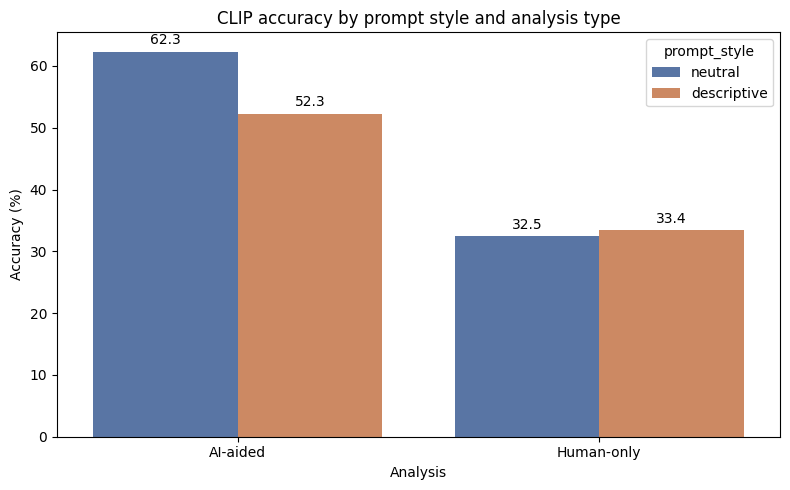

### 3.2 Full-Dataset Confusion Shift: Neutral vs. Descriptive Prompts
Comparing the 30-genre confusion matrices isolates the impact of prompt wording on the model's decision boundaries without the confounding variable of dataset size.   

Evaluating the exact same 30-class dataset allows for a direct comparison between the neutral prompt matrix and the descriptive prompt matrix.   

The error distribution across the 30 categories shifts significantly rather than improving uniformly, demonstrating that descriptive keywords reroute the model's visual shortcuts.   

While the model struggles to disentangle conceptually similar genres in both settings, the specific clusters of misclassification change dramatically based on the text prompt.

| Neutral Prompts | Descriptive Prompts |
| :---: | :---: |
| 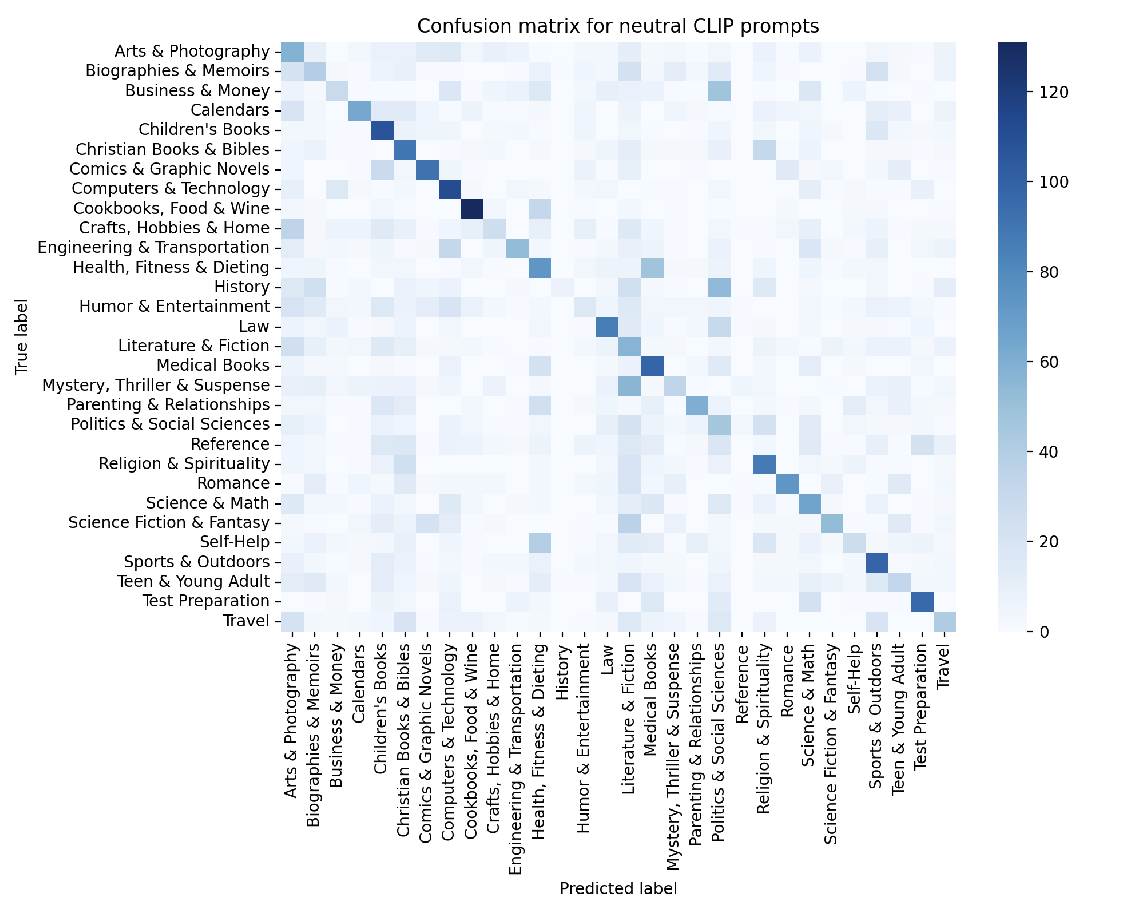 | 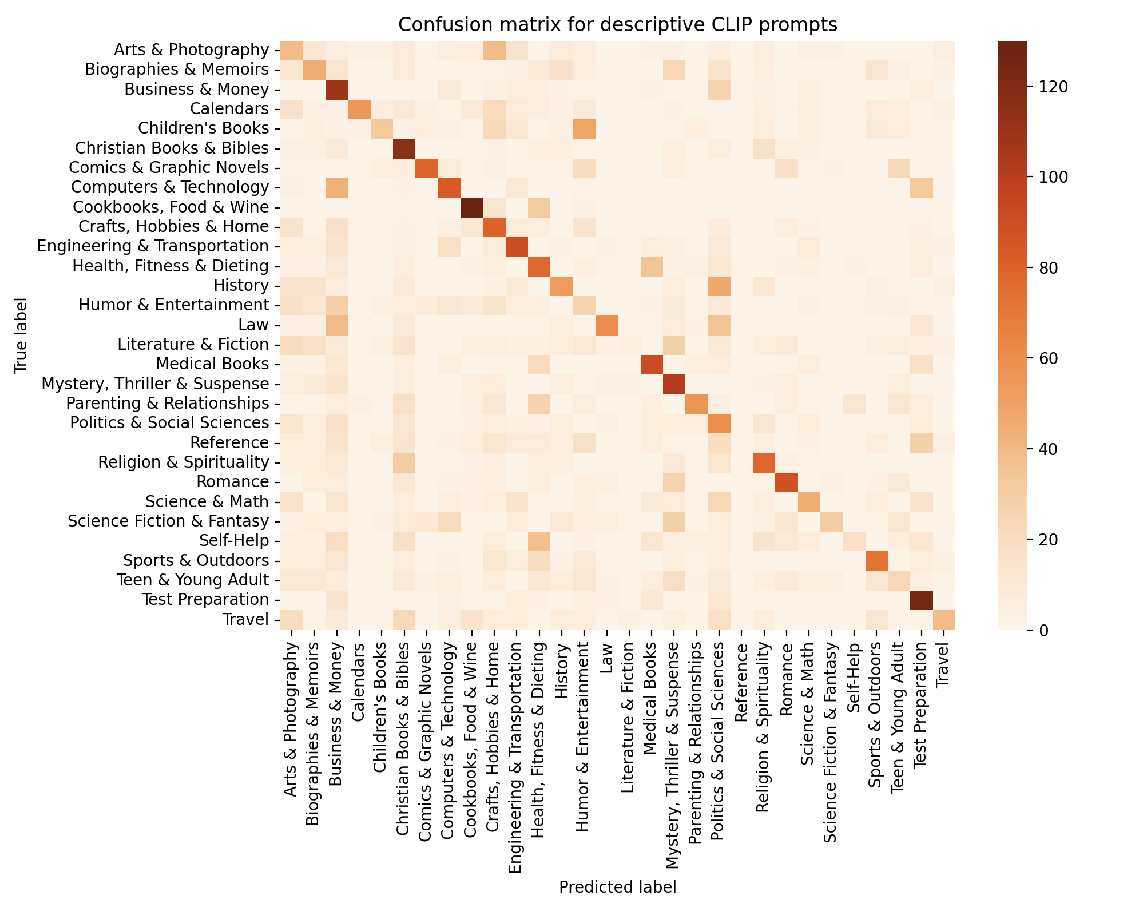 |



### 3.3 Visual Shortcuts: The Brightness Bias

CLIP appears to use color palettes and brightness as a proxy for genre.   

When analyzing Romance covers, the model consistently misclassified darker covers as "Mystery, Thriller & Suspense".   

The darkest quartile of Romance covers were misclassified as Thrillers 23.2% of the time, compared to only 4.0% for the brightest quartile.   


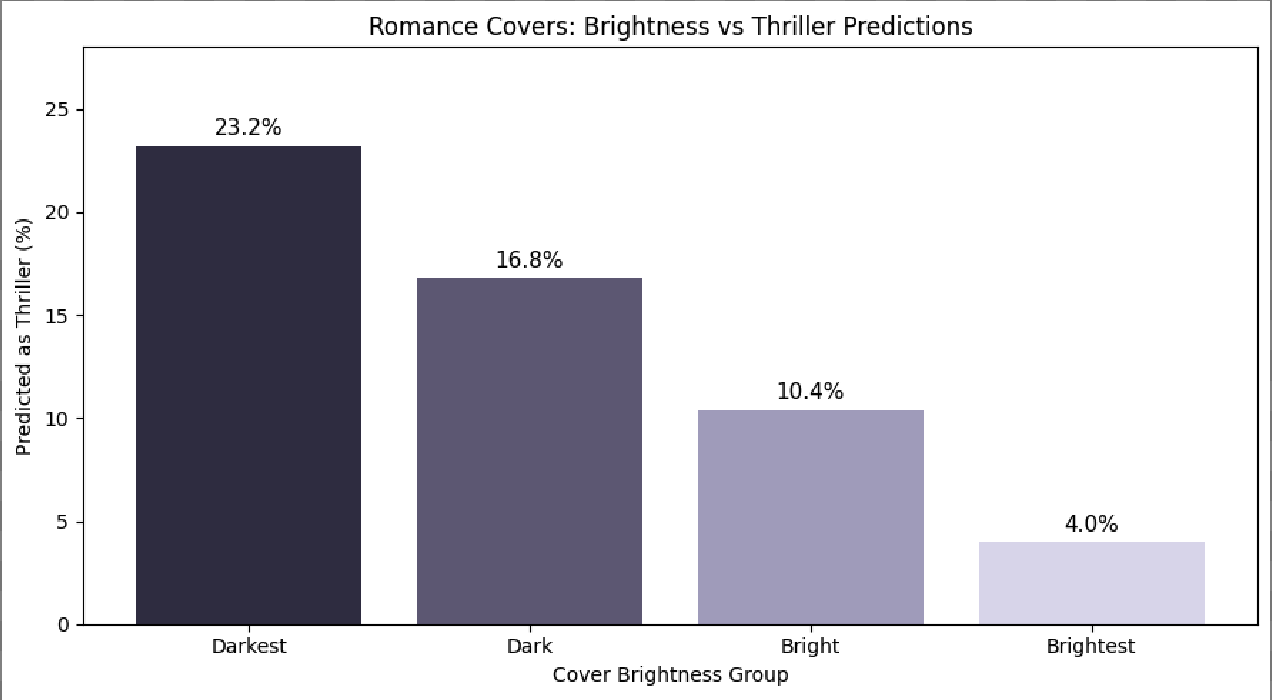

### 3.4 Object-Level Stereotypes: The Face Presence Effect

The model struggles to separate the core genre from literal object associations.   

History book covers featuring a detectable human face were classified as "Biographies & Memoirs" 54.5% of the time.   

In contrast, History covers without a detected face were only misclassified as Biographies 23.3% of the time.   

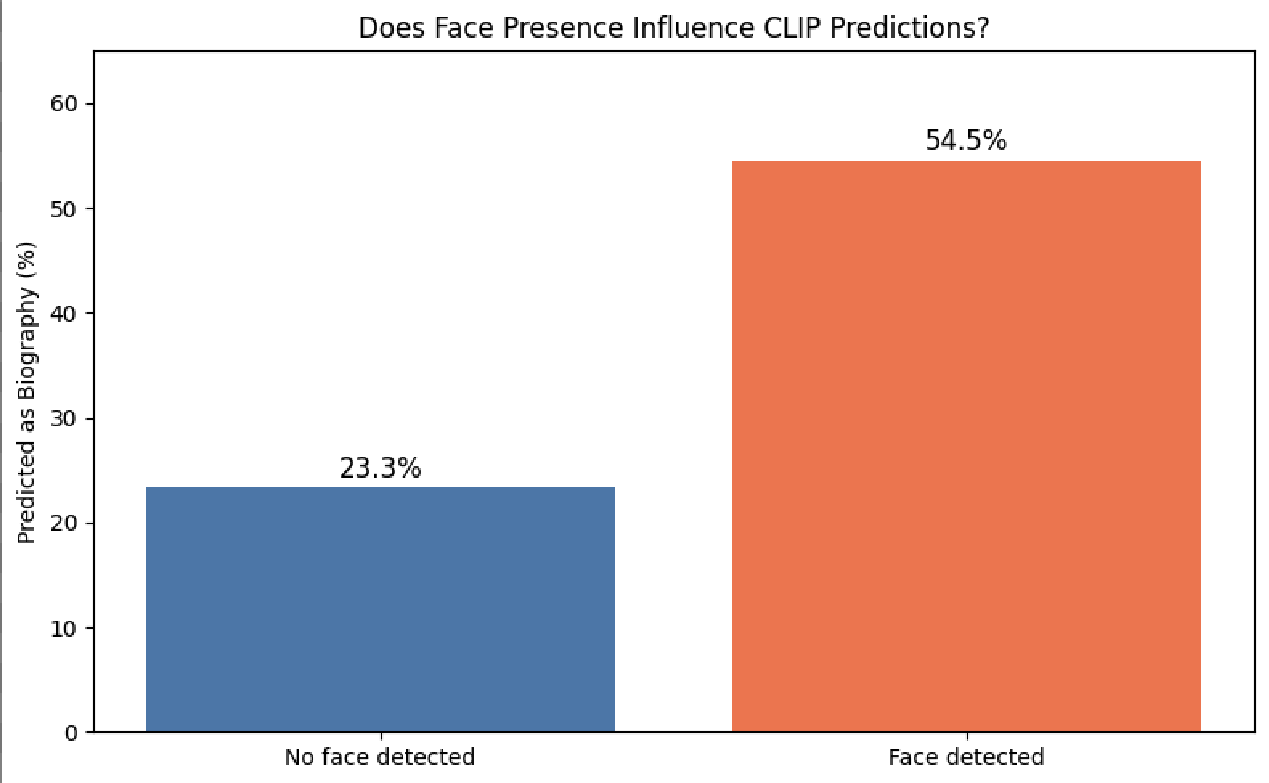

### 3.5 Confident Hallucinations

While correct predictions generally exhibited higher average confidence (0.717) than incorrect ones (0.559), the model still produced "confident errors".   

Even at a strict 95% confidence threshold, the model still made 15 incorrect predictions.   

This indicates that visual stereotypes (like dark colors or faces) can trick the model into outputting wrong genres with extremely high certainty.   

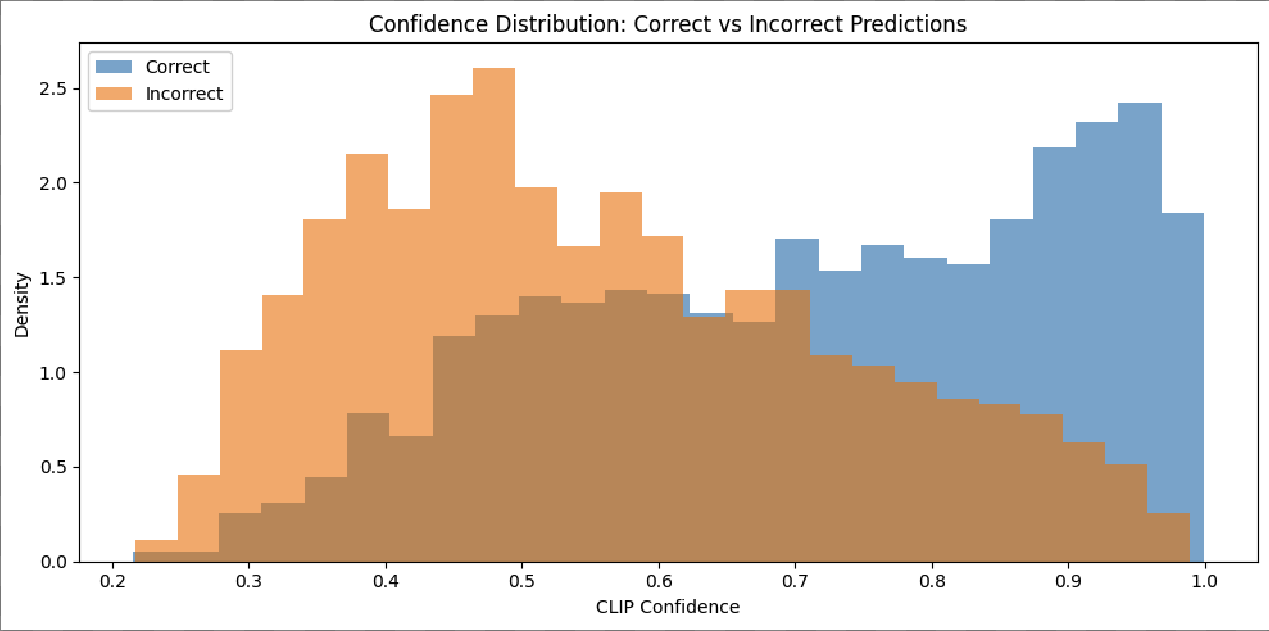



## 4. Next Steps: Phase II (White-Box Analysis)

In Phase II, we will transition from observing model behavior (inputs and outputs) to investigating what the model actually learned. We will open the CLIP black box to analyze its internal representations, specifically focusing on diagnosing the visual shortcuts and error clusters identified in Phase I.   


Phase II Investigative Roadmap:

Embedding Space Projections (UMAP/PCA): We will extract the final image features for our dataset and project them into a 2D latent space. We hypothesize that misclassified "dark Romance" covers are mapped closer to the "Thriller" cluster than the "Romance" cluster.

Attention Map Visualization: We will extract CLIP's token-to-patch cross-attention maps to understand where the model is looking. For History covers misclassified as Biographies, we will visualize if the model's attention is disproportionately focused on the human face rather than the background context.   

Prompt-Induced Latent Shifts: We will investigate how changing from neutral to descriptive text prompts physically shifts the text-embedding boundaries within the latent space, explaining the massive 40%+ prediction change observed in Phase I.

